# Preparation

In [ ]:
#@title Import Libs
#@markdown All libraries import goes over here

import os
import glob
import time
import joblib
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

In [ ]:
#@title Import Datasets

USE_MY_DRIVE = True #@param {type:"boolean"}
#@markdown > If you decided to **USE_MY_DRIVE** make sure to first run the latest version of [**02_data_preparation.ipynb**](https://colab.research.google.com/drive/1mdcqA8y9RN-pgtv3hRnDm2ZsheJqQnSe?usp=drive_link) with save to drive on
SHARED_FOLDER_URL = 'https://drive.google.com/drive/folders/1oj1cqdfyh1ouXThXJbjgamLA6H5nX8nF'

data_dir = 'processed_data'
loaded_from_my_drive = False

if USE_MY_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        drive_path = '/content/drive/MyDrive/DataScience-ProjectUAS/processed_data'
        if os.path.exists(f'{drive_path}/dataset_1_splits.pkl'):
            data_dir = drive_path
            loaded_from_my_drive = True
            print(f"Loaded from personal Google Drive: {data_dir}")
    except ImportError:
        pass

if not loaded_from_my_drive:
    os.makedirs(data_dir, exist_ok=True)
    if not glob.glob(f'{data_dir}/**/dataset_1_splits.pkl', recursive=True):
        print("Downloading splits from shared Google Drive folder...")
        subprocess.run(
            ['gdown', '--folder', SHARED_FOLDER_URL, '-O', data_dir, '--remaining-ok'],
            check=True
        )
    matched = glob.glob(f'{data_dir}/**/dataset_1_splits.pkl', recursive=True)
    data_dir = os.path.dirname(matched[0])
    print(f"Loaded from shared Drive fallback: {data_dir}")

dataset_1 = joblib.load(f'{data_dir}/dataset_1_splits.pkl')
dataset_2 = joblib.load(f'{data_dir}/dataset_2_splits.pkl')
dataset_3 = joblib.load(f'{data_dir}/dataset_3_splits.pkl')

print("All datasets ready for modeling.")

Mounted at /content/drive
Loaded from personal Google Drive: /content/drive/MyDrive/DataScience-ProjectUAS/processed_data
All datasets ready for modeling.


# Model Design: XGBoost Regressor

In [ ]:
#@title Model Configuration & Initial Hyperparameters

device = 'cuda' if torch.cuda.is_available() else 'cpu'

datasets_splits = {
    'Dataset 1': dataset_1,
    'Dataset 2': dataset_2,
    'Dataset 3': dataset_3
}

xgb_initial_params = {
    'n_estimators': 100,
    'learning_rate': 0.1,
    'max_depth': 6,
    'tree_method': 'hist',
    'device': device,
    'random_state': 42
}

os.makedirs('models', exist_ok=True)
print(f"Active device : {device.upper()}")
print("Initial params:", xgb_initial_params)

Active device : CUDA
Initial params: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 6, 'tree_method': 'hist', 'device': 'cuda', 'random_state': 42}


# Training & Validation Evaluation

In [ ]:
#@title Train XGBoost Regressor

trained_models = {}
training_times = {}

for nama, split in datasets_splits.items():
    start_time = time.time()
    model = XGBRegressor(**xgb_initial_params)
    model.fit(split['X_train'], split['y_train'])
    elapsed = time.time() - start_time

    trained_models[nama] = model
    training_times[nama] = round(elapsed, 2)
    print(f"{nama} selesai dilatih dalam {elapsed:.2f} detik.")

Dataset 1 selesai dilatih dalam 0.74 detik.
Dataset 2 selesai dilatih dalam 2.42 detik.
Dataset 3 selesai dilatih dalam 0.21 detik.


In [ ]:
#@title Evaluate Model on Train & Validation Sets
#@markdown Menghitung RMSE, MAE, dan $R^2$ pada Validation Set untuk mencatat performa awal serta memantau gap generalisasi.

val_results = []

for nama, split in datasets_splits.items():
    model = trained_models[nama]

    y_train_pred = model.predict(split['X_train'])
    y_val_pred = model.predict(split['X_val'])

    val_results.append({
        'Dataset': nama,
        'Train_RMSE': root_mean_squared_error(split['y_train'], y_train_pred),
        'Val_RMSE': root_mean_squared_error(split['y_val'], y_val_pred),
        'Val_MAE': mean_absolute_error(split['y_val'], y_val_pred),
        'Val_R2': r2_score(split['y_val'], y_val_pred),
        'Train_Time_Sec': training_times[nama]
    })

val_metrics_df = pd.DataFrame(val_results)
display(val_metrics_df.round(4))

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [07:58:19] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


,Dataset,Train_RMSE,Val_RMSE,Val_MAE,Val_R2,Train_Time_Sec
0,Dataset 1,17242.9707,19492.5781,12199.2451,0.9493,0.74
1,Dataset 2,0.4984,0.5004,0.3993,0.9128,2.42
2,Dataset 3,3.6973,5.3472,4.2781,0.9804,0.21


# Feature Importance & Residual Diagnostics

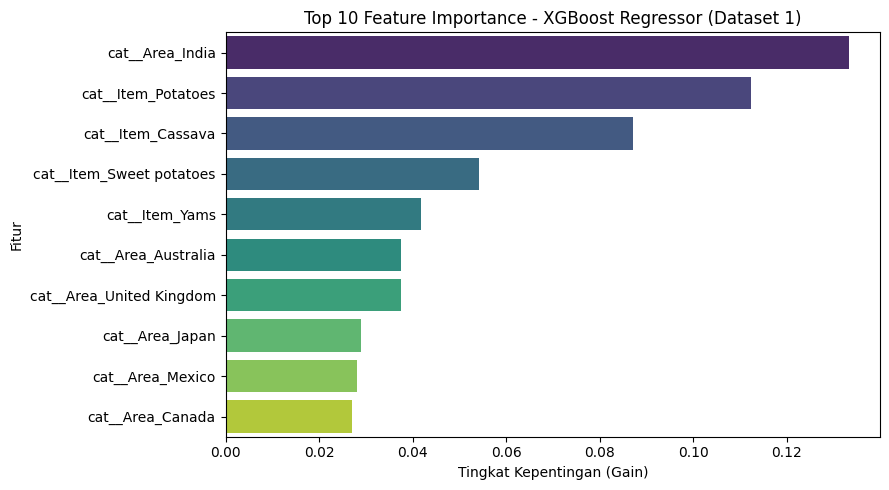

In [ ]:
#@title Top 10 Feature Importances (Dataset 1)
#@markdown 10 fitur dengan kontribusi gain tertinggi pada XGBoost decission tree.

xgb_d1 = trained_models['Dataset 1']
feat_names = dataset_1['feature_names']

importance_df = pd.DataFrame({
    'Feature': feat_names,
    'Importance': xgb_d1.feature_importances_
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title('Top 10 Feature Importance - XGBoost Regressor (Dataset 1)')
plt.xlabel('Tingkat Kepentingan (Gain)')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

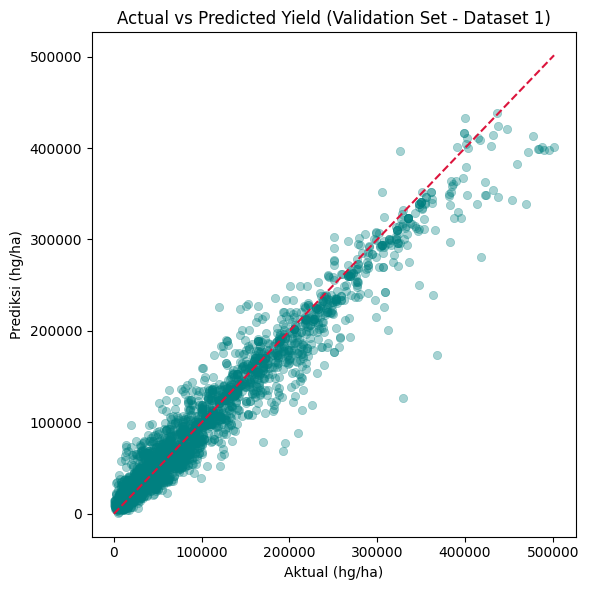

In [ ]:
#@title Actual vs Predicted Plot (Validation Set - Dataset 1)

y_val_actual = dataset_1['y_val']
y_val_pred = trained_models['Dataset 1'].predict(dataset_1['X_val'])

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_val_actual, y=y_val_pred, alpha=0.35, color='teal', edgecolor=None)
max_val = max(y_val_actual.max(), y_val_pred.max())
plt.plot([0, max_val], [0, max_val], color='crimson', linestyle='--', linewidth=1.5)
plt.title('Actual vs Predicted Yield (Validation Set - Dataset 1)')
plt.xlabel('Aktual (hg/ha)')
plt.ylabel('Prediksi (hg/ha)')
plt.tight_layout()
plt.show()

# Save Artifacts

In [ ]:
#@title Export Validation Metrics & Trained Models

SAVE_MODELS_TO_DRIVE = True #@param {type:"boolean"}

model_dir = 'models'
if SAVE_MODELS_TO_DRIVE and os.path.exists('/content/drive/MyDrive'):
    model_dir = '/content/drive/MyDrive/DataScience-ProjectUAS/models'

os.makedirs(model_dir, exist_ok=True)

val_metrics_df.to_csv(f'{model_dir}/advanced_xgb_val_metrics.csv', index=False)

for nama, model in trained_models.items():
    prefix = nama.lower().replace(" ", "_")
    model.save_model(f'{model_dir}/{prefix}_xgb_initial.json')

print(f"Metrics and model artifacts saved to: {model_dir}")

Metrics and model artifacts saved to: /content/drive/MyDrive/DataScience-ProjectUAS/models
